# Topic 4: Architectures Based on Recurrent Neural Networks (RNNs)
## Thí nghiệm & Bài tập thực hành Deep Learning (PyTorch)

Notebook này bao gồm đầy đủ lý thuyết, bài tập thực hành và mã nguồn triển khai bằng **PyTorch** cho các kiến trúc:
- **Vanilla RNN**
- **LSTM (Long Short-Term Memory)**
- **GRU (Gated Recurrent Unit)**
- **Bidirectional RNN (BiLSTM)**
- **Custom LSTM Cell** (Lập trình cổng LSTM thủ công)

### 1. Cài đặt môi trường & Import thư viện

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt

# Thiết lập device (GPU nếu có)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Đang sử dụng thiết bị: {device}")

Đang sử dụng thiết bị: cpu


--- 
### 2. Practice 1: Phân loại Cảm xúc Văn bản (Sentiment Analysis)
Mô hình tổng quát hỗ trợ linh hoạt lựa chọn giữa **Vanilla RNN, GRU, LSTM** và **Bidirectional**.

In [6]:
class SentimentClassifier(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim, output_dim, model_type='LSTM', bidirectional=False, num_layers=1):
        super(SentimentClassifier, self).__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim)
        self.model_type = model_type
        self.bidirectional = bidirectional
        
        if model_type == 'RNN':
            self.rnn = nn.RNN(embed_dim, hidden_dim, num_layers=num_layers, batch_first=True, bidirectional=bidirectional)
        elif model_type == 'GRU':
            self.rnn = nn.GRU(embed_dim, hidden_dim, num_layers=num_layers, batch_first=True, bidirectional=bidirectional)
        elif model_type == 'LSTM':
            self.rnn = nn.LSTM(embed_dim, hidden_dim, num_layers=num_layers, batch_first=True, bidirectional=bidirectional)
            
        num_directions = 2 if bidirectional else 1
        self.fc = nn.Linear(hidden_dim * num_directions, output_dim)
        self.dropout = nn.Dropout(0.3)
        
    def forward(self, text):
        # text shape: [batch_size, seq_len]
        embedded = self.dropout(self.embedding(text)) # [batch_size, seq_len, embed_dim]
        
        if self.model_type == 'LSTM':
            output, (hidden, cell) = self.rnn(embedded)
        else:
            output, hidden = self.rnn(embedded)
            
        if self.bidirectional:
            # Kết hợp hidden state của cả 2 chiều (chiều tiến và chiều lùi)
            hidden_last = torch.cat((hidden[-2,:,:], hidden[-1,:,:]), dim=1)
        else:
            hidden_last = hidden[-1,:,:]
            
        return self.fc(hidden_last)

# Chạy thử nghiệm mô hình
VOCAB_SIZE = 5000
EMBED_DIM = 100
HIDDEN_DIM = 128
OUTPUT_DIM = 2

model_bilstm = SentimentClassifier(VOCAB_SIZE, EMBED_DIM, HIDDEN_DIM, OUTPUT_DIM, model_type='LSTM', bidirectional=True).to(device)
print(model_bilstm)

# Giả lập 1 batch dữ liệu đầu vào [batch_size=4, seq_len=10]
dummy_input = torch.randint(0, VOCAB_SIZE, (4, 10)).to(device)
output = model_bilstm(dummy_input)
print("Shape đầu ra dự đoán:", output.shape) # [4, 2]

SentimentClassifier(
  (embedding): Embedding(5000, 100)
  (rnn): LSTM(100, 128, batch_first=True, bidirectional=True)
  (fc): Linear(in_features=256, out_features=2, bias=True)
  (dropout): Dropout(p=0.3, inplace=False)
)
Shape đầu ra dự đoán: torch.Size([4, 2])


--- 
### 3. Practice 2: Mô hình Sinh Chuỗi Ký tự (Char-RNN Text Generation)
Huấn luyện mạng RNN dự đoán ký tự tiếp theo trong chuỗi văn bản.

In [7]:
class CharRNN(nn.Module):
    def __init__(self, vocab_size, hidden_dim, num_layers=2):
        super(CharRNN, self).__init__()
        self.hidden_dim = hidden_dim
        self.num_layers = num_layers
        self.embedding = nn.Embedding(vocab_size, hidden_dim)
        self.lstm = nn.LSTM(hidden_dim, hidden_dim, num_layers, batch_first=True)
        self.fc = nn.Linear(hidden_dim, vocab_size)
        
    def forward(self, x, hc):
        out = self.embedding(x)
        out, (h, c) = self.lstm(out, hc)
        out = out.reshape(-1, self.hidden_dim)
        out = self.fc(out)
        return out, (h, c)

    def init_hidden(self, batch_size):
        return (torch.zeros(self.num_layers, batch_size, self.hidden_dim).to(device),
                torch.zeros(self.num_layers, batch_size, self.hidden_dim).to(device))

# Kiểm tra khởi tạo Char-RNN
char_model = CharRNN(vocab_size=65, hidden_dim=128, num_layers=2).to(device)
print(char_model)

CharRNN(
  (embedding): Embedding(65, 128)
  (lstm): LSTM(128, 128, num_layers=2, batch_first=True)
  (fc): Linear(in_features=128, out_features=65, bias=True)
)


--- 
### 4. Practice 3: Tự lập trình Cổng LSTM (Custom LSTM Cell in PyTorch)
Lập trình thủ công công thức các cổng Forget ($f_t$), Input ($i_t$), Candidate ($	ilde{c}_t$), và Output ($o_t$).

$$
\begin{aligned}
f_t &= \sigma(W_f x_t + U_f h_{t-1} + b_f) \\
i_t &= \sigma(W_i x_t + U_i h_{t-1} + b_i) \\
\tilde{c}_t &= \tanh(W_c x_t + U_c h_{t-1} + b_c) \\
c_t &= f_t \odot c_{t-1} + i_t \odot \tilde{c}_t \\
o_t &= \sigma(W_o x_t + U_o h_{t-1} + b_o) \\
h_t &= o_t \odot \tanh(c_t)
\end{aligned}
$$

In [8]:
class CustomLSTMCell(nn.Module):
    def __init__(self, input_dim, hidden_dim):
        super(CustomLSTMCell, self).__init__()
        self.input_dim = input_dim
        self.hidden_dim = hidden_dim
        
        # Gộp ma trận trọng số cho 4 cổng: [input_dim + hidden_dim, 4 * hidden_dim]
        self.weight_ih = nn.Parameter(torch.randn(4 * hidden_dim, input_dim) * 0.1)
        self.weight_hh = nn.Parameter(torch.randn(4 * hidden_dim, hidden_dim) * 0.1)
        self.bias = nn.Parameter(torch.zeros(4 * hidden_dim))
        
    def forward(self, x_t, states):
        h_prev, c_prev = states
        
        # Tính toán kết hợp tuyến tính cho 4 cổng
        gates = (torch.matmul(x_t, self.weight_ih.t()) +
                 torch.matmul(h_prev, self.weight_hh.t()) + self.bias)
        
        # Chia nhỏ kết quả thành 4 cổng
        f_gate, i_gate, c_cand, o_gate = gates.chunk(4, 1)
        
        f = torch.sigmoid(f_gate)       # Forget gate
        i = torch.sigmoid(i_gate)       # Input gate
        c_tilde = torch.tanh(c_cand)    # Candidate cell state
        o = torch.sigmoid(o_gate)       # Output gate
        
        c_t = f * c_prev + i * c_tilde  # Trạng thái Cell mới
        h_t = o * torch.tanh(c_t)       # Trạng thái Ẩn mới
        
        return h_t, (h_t, c_t)

# Kiểm tra Custom LSTM Cell
cell = CustomLSTMCell(input_dim=10, hidden_dim=20).to(device)
x_t = torch.randn(2, 10).to(device)
h_0 = torch.zeros(2, 20).to(device)
c_0 = torch.zeros(2, 20).to(device)

h_1, (h_1, c_1) = cell(x_t, (h_0, c_0))
print("Custom Cell Output h_1 shape:", h_1.shape)
print("Custom Cell Output c_1 shape:", c_1.shape)

Custom Cell Output h_1 shape: torch.Size([2, 20])
Custom Cell Output c_1 shape: torch.Size([2, 20])


--- 
### 5. Practice 4: Dự báo Chuỗi Thời gian & So sánh Loss (Time Series & Loss Plotting)
Sinh dữ liệu sóng Sine có nhiễu, sử dụng GRU để dự báo chuỗi thời gian và trực quan hóa Loss.

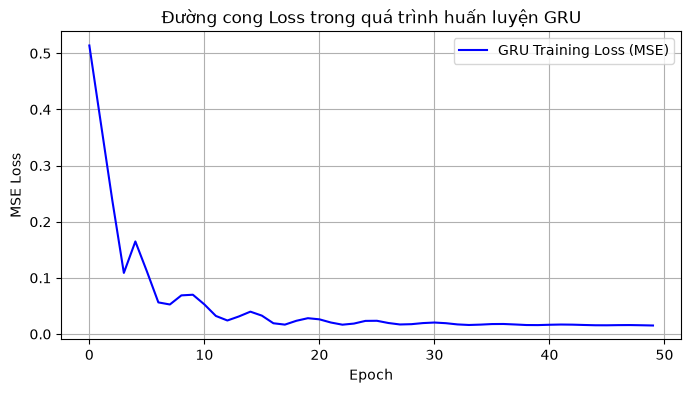

In [10]:
# 1. Sinh dữ liệu chuỗi thời gian sóng Sine giả lập
t = np.linspace(0, 100, 1000)
data = np.sin(t) + np.random.normal(0, 0.1, 1000)

# Tạo dataset windowing
def create_dataset(data, window_size=20):
    X, y = [], []
    for i in range(len(data) - window_size):
        X.append(data[i:i+window_size])
        y.append(data[i+window_size])
    return torch.tensor(np.array(X), dtype=torch.float32), torch.tensor(np.array(y), dtype=torch.float32)

X, y = create_dataset(data, window_size=20)
X = X.unsqueeze(-1) # reshape sang [N, seq_len, input_dim=1]

# 2. Mô hình GRU Dự báo chuỗi thời gian
class TimeSeriesGRU(nn.Module):
    def __init__(self, input_dim=1, hidden_dim=32, num_layers=2):
        super(TimeSeriesGRU, self).__init__()
        self.gru = nn.GRU(input_dim, hidden_dim, num_layers, batch_first=True)
        self.fc = nn.Linear(hidden_dim, 1)
        
    def forward(self, x):
        out, _ = self.gru(x)
        return self.fc(out[:, -1, :])

gru_model = TimeSeriesGRU().to(device)
criterion = nn.MSELoss()
optimizer = optim.Adam(gru_model.parameters(), lr=0.01)

# 3. Huấn luyện và lưu Loss
losses = []
epochs = 50

X_dev = X.to(device)
y_dev = y.to(device)

for epoch in range(epochs):
    optimizer.zero_grad()
    preds = gru_model(X_dev).squeeze(-1)
    loss = criterion(preds, y_dev)
    loss.backward()
    optimizer.step()
    losses.append(loss.item())

# 4. Vẽ đồ thị đường cong Loss
plt.figure(figsize=(8, 4))
plt.plot(losses, label='GRU Training Loss (MSE)', color='blue')
plt.title('Đường cong Loss trong quá trình huấn luyện GRU')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.grid(True)
plt.legend()
plt.show()